# 02b. Trực quan hóa dữ liệu và insight
Mỗi hình được lưu vào `figures/` để chèn vào báo cáo. Nhãn: `HeartDisease` (1 = có bệnh).

In [1]:
import sys; sys.path.append('..')
from src.common import *
import warnings; warnings.filterwarnings('ignore')
df = load_clean()
df['Giới'] = df.sex.map({0: 'Nữ', 1: 'Nam'})
df['Nhãn'] = df[TARGET].map({0: 'Không bệnh', 1: 'Có bệnh'})
PAL = {'Không bệnh': '#8ecae6', 'Có bệnh': '#e76f51'}
print(df.shape)

(302, 16)


## Hình 3.1. Phân bố tuổi theo giới tính

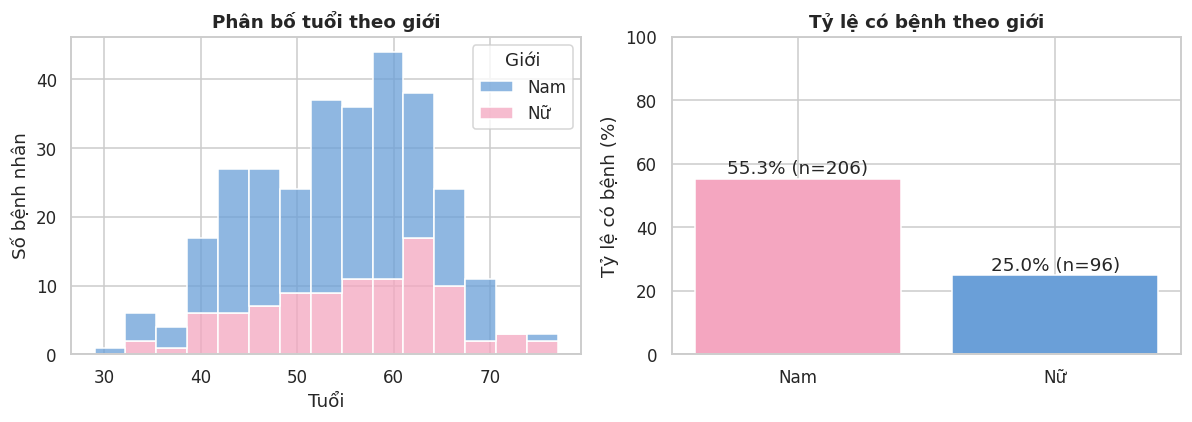

      count  mean  std   min   25%   50%   75%   max
Giới                                                
Nam   206.0  53.8  8.8  29.0  47.0  54.5  59.8  77.0
Nữ     96.0  55.7  9.4  34.0  49.8  57.0  63.0  76.0
       mean  count
Giới              
Nam   0.553    206
Nữ    0.250     96


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=df, x='age', hue='Giới', multiple='stack', bins=15, palette={'Nữ': '#f4a6c0', 'Nam': '#6a9fd8'}, ax=ax[0])
ax[0].set_title('Phân bố tuổi theo giới'); ax[0].set_xlabel('Tuổi'); ax[0].set_ylabel('Số bệnh nhân')
rate = df.groupby('Giới')[TARGET].agg(['mean', 'count'])
b = ax[1].bar(rate.index, rate['mean']*100, color=['#f4a6c0', '#6a9fd8'])
for r, (m, n) in zip(b, rate.values): ax[1].text(r.get_x()+r.get_width()/2, m*100+1.5, f'{m*100:.1f}% (n={int(n)})', ha='center')
ax[1].set_ylim(0, 100); ax[1].set_ylabel('Tỷ lệ có bệnh (%)'); ax[1].set_title('Tỷ lệ có bệnh theo giới')
savefig('fig_3_1_tuoi_gioi_tinh')
print(df.groupby('Giới').age.describe().round(1)); print(rate.round(3))

## Hình 3.2. Phân bố các chỉ số chính

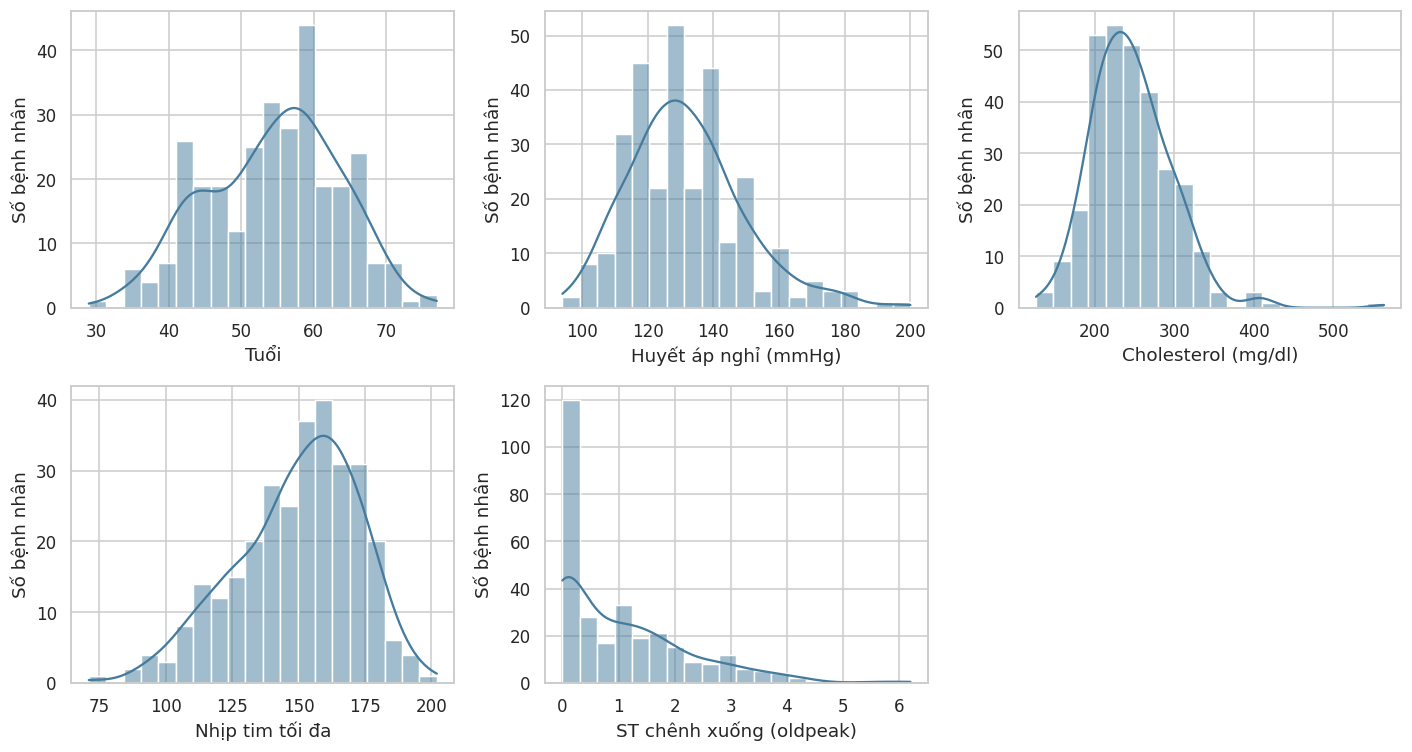

          age  trestbps    chol  thalach  oldpeak
mean    54.42    131.60  246.50   149.57     1.04
median  55.50    130.00  240.50   152.50     0.80
std      9.05     17.56   51.75    22.90     1.16
skew    -0.20      0.72    1.15    -0.53     1.27


In [3]:
cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
fig, ax = plt.subplots(2, 3, figsize=(13, 7)); ax = ax.ravel()
for a, c in zip(ax, cols):
    sns.histplot(df[c], kde=True, bins=20, ax=a, color='#457b9d'); a.set_xlabel(VN[c]); a.set_ylabel('Số bệnh nhân')
ax[-1].axis('off')
savefig('fig_3_2_phan_bo_chi_so')
print(df[cols].agg(['mean', 'median', 'std', 'skew']).round(2))

## Hình 3.3. Huyết áp và cholesterol so với bệnh tim

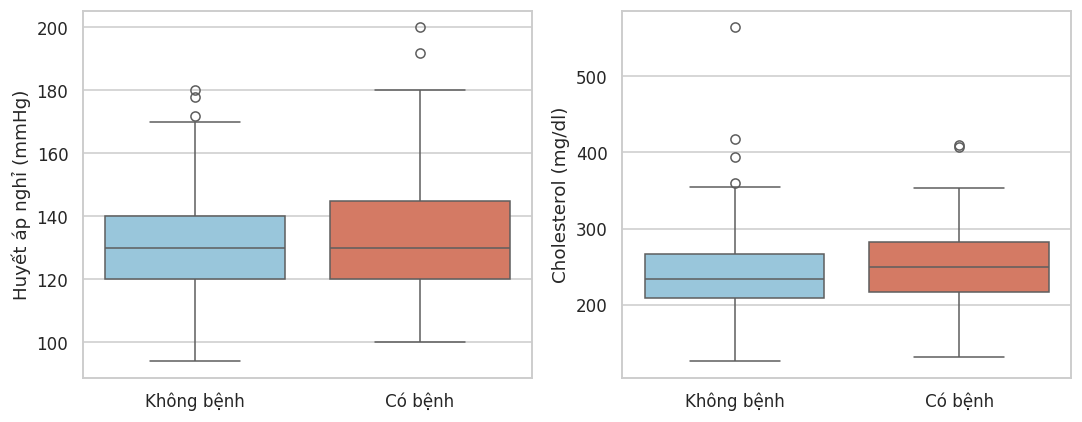

           trestbps          chol       
               mean median   mean median
Nhãn                                    
Có bệnh       134.4  130.0  251.1  249.0
Không bệnh    129.2  130.0  242.6  234.5
trestbps Mann-Whitney p = 0.0322
chol Mann-Whitney p = 0.0424


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, c in zip(ax, ['trestbps', 'chol']):
    sns.boxplot(data=df, x='Nhãn', y=c, palette=PAL, order=['Không bệnh', 'Có bệnh'], ax=a)
    a.set_xlabel(''); a.set_ylabel(VN[c])
savefig('fig_3_3_huyetap_cholesterol_vs_benh')
print(df.groupby('Nhãn')[['trestbps', 'chol']].agg(['mean', 'median']).round(1))
from scipy import stats
for c in ['trestbps', 'chol']:
    a_, b_ = df[df[TARGET]==1][c], df[df[TARGET]==0][c]
    print(c, 'Mann-Whitney p =', round(stats.mannwhitneyu(a_, b_).pvalue, 4))

## Hình 3.4. Tỷ lệ có bệnh theo nhóm chỉ số

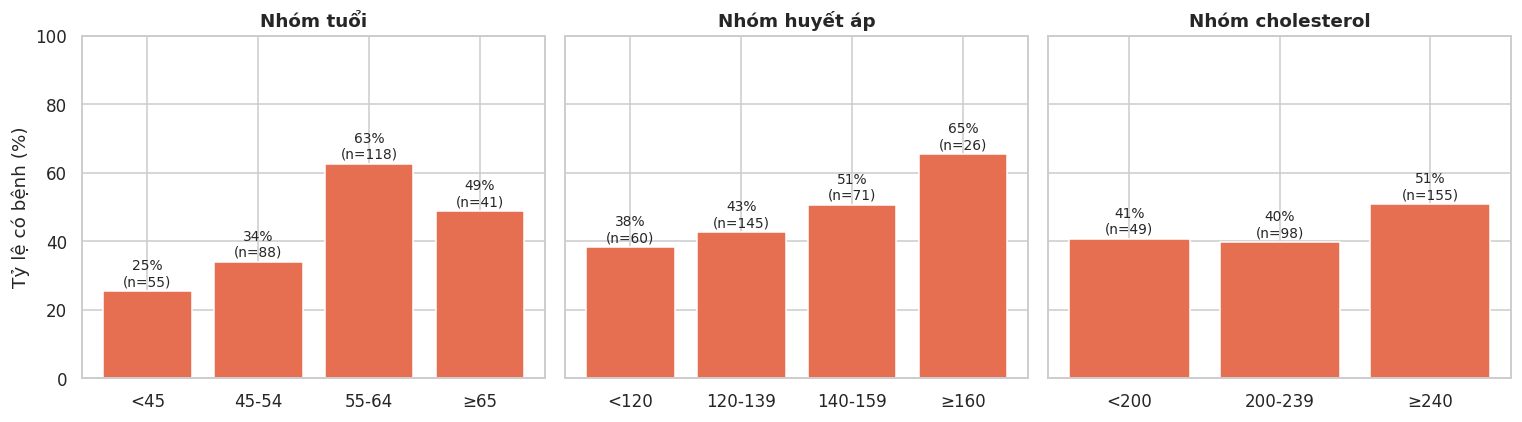

            mean  count
Nhóm tuổi              
<45        0.255     55
45-54      0.341     88
55-64      0.627    118
≥65        0.488     41
                mean  count
Nhóm huyết áp              
<120           0.383     60
120-139        0.428    145
140-159        0.507     71
≥160           0.654     26
                   mean  count
Nhóm cholesterol              
<200              0.408     49
200-239           0.398     98
≥240              0.510    155


In [5]:
df['Nhóm tuổi'] = pd.cut(df.age, [0, 44, 54, 64, 120], labels=['<45', '45-54', '55-64', '≥65'])
df['Nhóm huyết áp'] = pd.cut(df.trestbps, [0, 119, 139, 159, 400], labels=['<120', '120-139', '140-159', '≥160'])
df['Nhóm cholesterol'] = pd.cut(df.chol, [0, 199, 239, 1000], labels=['<200', '200-239', '≥240'])
fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for a, g in zip(ax, ['Nhóm tuổi', 'Nhóm huyết áp', 'Nhóm cholesterol']):
    t = df.groupby(g, observed=True)[TARGET].agg(['mean', 'count'])
    bars = a.bar(t.index.astype(str), t['mean']*100, color='#e76f51')
    for r, (m, n) in zip(bars, t.values): a.text(r.get_x()+r.get_width()/2, m*100+1.5, f'{m*100:.0f}%\n(n={int(n)})', ha='center', fontsize=9)
    a.set_title(g); a.set_ylim(0, 100)
ax[0].set_ylabel('Tỷ lệ có bệnh (%)')
savefig('fig_3_4_ty_le_nguy_co_theo_nhom')
for g in ['Nhóm tuổi', 'Nhóm huyết áp', 'Nhóm cholesterol']:
    print(df.groupby(g, observed=True)[TARGET].agg(['mean', 'count']).round(3))

## Hình 3.5. Loại đau ngực và đau thắt ngực khi gắng sức

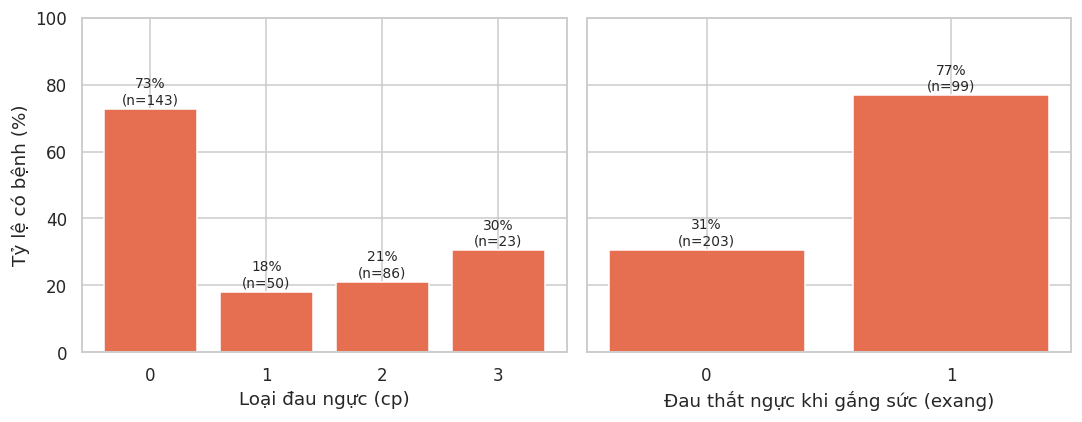

     mean  count
cp              
0   0.727    143
1   0.180     50
2   0.209     86
3   0.304     23
        mean  count
exang              
0      0.305    203
1      0.768     99


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for a, c, lab in zip(ax, ['cp', 'exang'], ['Loại đau ngực (cp)', 'Đau thắt ngực khi gắng sức (exang)']):
    t = df.groupby(c)[TARGET].agg(['mean', 'count'])
    bars = a.bar(t.index.astype(str), t['mean']*100, color='#e76f51')
    for r, (m, n) in zip(bars, t.values): a.text(r.get_x()+r.get_width()/2, m*100+1.5, f'{m*100:.0f}%\n(n={int(n)})', ha='center', fontsize=9)
    a.set_xlabel(lab); a.set_ylim(0, 100)
ax[0].set_ylabel('Tỷ lệ có bệnh (%)')
savefig('fig_3_5_cp_exang')
for c in ['cp', 'exang']: print(df.groupby(c)[TARGET].agg(['mean', 'count']).round(3))

## Hình 3.6. Nhịp tim tối đa theo tuổi

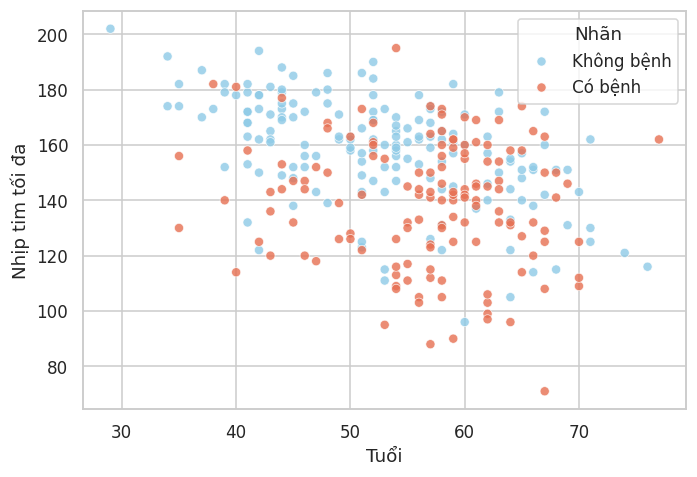

            thalach  oldpeak
Nhãn                        
Có bệnh      139.10     1.59
Không bệnh   158.38     0.59


In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.scatterplot(data=df, x='age', y='thalach', hue='Nhãn', palette=PAL, alpha=.8, ax=ax)
ax.set_xlabel('Tuổi'); ax.set_ylabel(VN['thalach'])
savefig('fig_3_6_thalach_theo_tuoi')
print(df.groupby('Nhãn')[['thalach', 'oldpeak']].mean().round(2))

## Hình 3.7. Ma trận tương quan

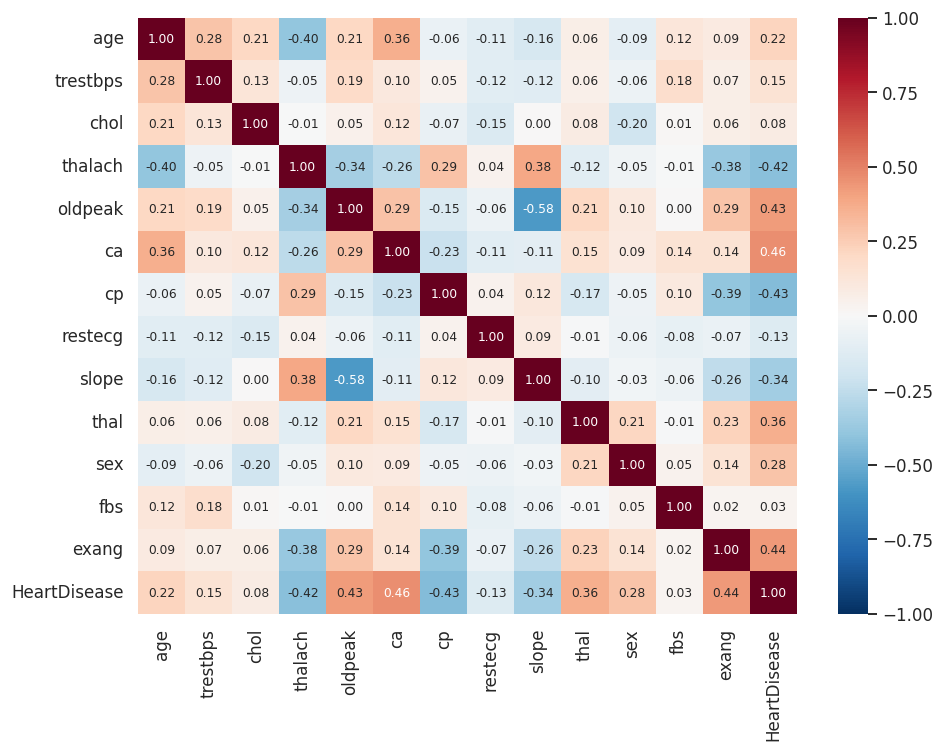

ca          0.46
exang       0.44
cp         -0.43
oldpeak     0.43
thalach    -0.42
thal        0.36
slope      -0.34
sex         0.28
age         0.22
trestbps    0.15
restecg    -0.13
chol        0.08
fbs         0.03
Name: HeartDisease, dtype: float64


In [8]:
corr = df[FEATURES + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax, annot_kws={'size': 8})
savefig('fig_3_7_ma_tran_tuong_quan')
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(2))